In [6]:
import pandas as pd

data_root = "./Final_SOCal_dataset.csv"

data = pd.read_csv(data_root)
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 65796 entries, 0 to 65795
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   station              65796 non-null  str    
 1   name                 65796 non-null  str    
 2   date                 65796 non-null  str    
 3   year                 65796 non-null  int64  
 4   tmin_lag1            65495 non-null  float64
 5   dtr_lag1             65212 non-null  float64
 6   dayofyear            65796 non-null  int64  
 7   days_since_rain      65796 non-null  float64
 8   oni_lag              65796 non-null  float64
 9   prcp_sum30           65571 non-null  float64
 10  prcp_lag1            65514 non-null  float64
 11  station_code         65796 non-null  int64  
 12  hot_day              65513 non-null  float64
 13  hot_night            65686 non-null  float64
 14  coverage             65796 non-null  float64
 15  prev_hot_nights      62717 non-null  float64
 1

In [7]:
# remove features that will immediately leak the result
FEATURES = ["tmin_lag1", "dtr_lag1", "dayofyear", "days_since_rain", "oni_lag", "prcp_sum30", "prcp_lag1", "station_code"]

TRAIN_END_YEAR = 2015          # train: 1950–2015, test: 2016–2025
data = data.dropna()
train = data[data["year"] <= TRAIN_END_YEAR]
test = data[data["year"] > TRAIN_END_YEAR]

In [8]:
# now create a logistic regression model for target_1
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

model1 = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model1.fit(train[FEATURES], train["hot_day"])

model2 = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model2.fit(train[FEATURES], train["hot_night"])

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

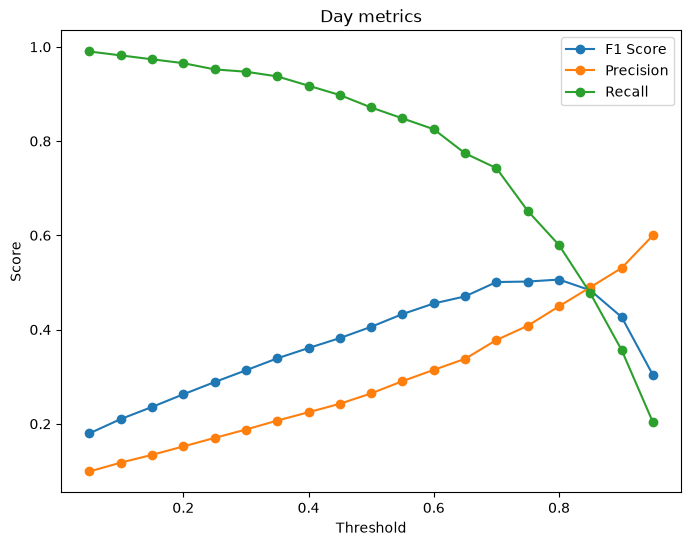

Best threshold for F1 score: 0.8
Confusion Matrix:
[[7712  430]
 [ 255  351]]
AUC: 91.58%
Precision: 44.94%
Recall: 57.92%
F1 Score: 50.61%


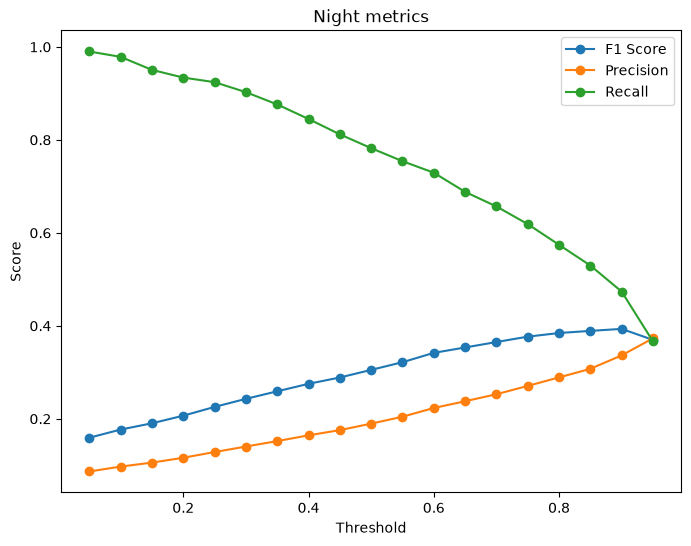

Best threshold for F1 score: 0.9000000000000001
Confusion Matrix:
[[7951  191]
 [ 390  216]]
AUC: 91.58%
Precision: 53.07%
Recall: 35.64%
F1 Score: 42.65%


In [9]:
import numpy as np
import matplotlib.pyplot as plt

for (title, model) in [("Day", model1), ("Night", model2)]:
	proba = model.predict_proba(test[FEATURES])[:, 1]
	thresholds = np.arange(0.05, 0.96, 0.05)
	f1s = [f1_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]
	precisions = [precision_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]
	recalls = [recall_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]

	best = thresholds[np.argmax(f1s)]

	plt.figure(figsize=(8, 6))
	plt.plot(thresholds, f1s, marker='o', label='F1 Score')
	plt.plot(thresholds, precisions, marker='o', label='Precision')
	plt.plot(thresholds, recalls, marker='o', label='Recall')
	plt.xlabel("Threshold")
	plt.ylabel("Score")
	plt.title(f"{title} metrics")
	plt.legend()
	plt.show()

	print("Best threshold for F1 score:", best)

	proba = model1.predict_proba(test[FEATURES])[:, 1]

	y_pred = (proba >= best).astype(int)
	cm = confusion_matrix(test["hot_day"], y_pred, labels=[0, 1])
	auc = roc_auc_score(test["hot_day"], proba)
	print("Confusion Matrix:")
	print(cm)
	print("AUC: {:.2f}%".format(100 * auc))
	print("Precision: {:.2f}%".format(100 * precision_score(test["hot_day"], y_pred)))
	print("Recall: {:.2f}%".format(100 * recall_score(test["hot_day"], y_pred)))
	print("F1 Score: {:.2f}%".format(100 * f1_score(test["hot_day"], y_pred)))

In [10]:
# save the normal models
import pickle
def save_model(model, test_feature, train_feature, test_target, train_target, filename):
    pickle.dump((model, test_feature, train_feature, test_target, train_target), open(filename, "wb"))
    print(f"Model saved to {filename}")
save_model(model1, test[FEATURES], train[FEATURES], test["hot_day"], train["hot_day"], "model_hot_day.sav")
save_model(model2, test[FEATURES], train[FEATURES], test["hot_night"], train["hot_night"], "model_hot_night.sav")

Model saved to model_hot_day.sav
Model saved to model_hot_night.sav


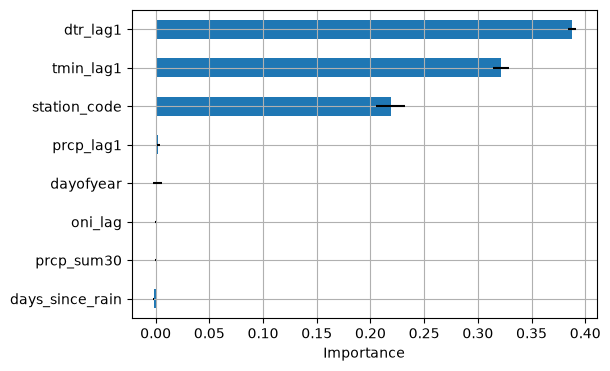

Useful features: ['tmin_lag1', 'dtr_lag1', 'station_code']


In [11]:
# use importance to find out which features can be removed
from sklearn.inspection import permutation_importance

r = permutation_importance(model1, test[FEATURES], test["hot_day"],
                           scoring="average_precision", n_repeats=100, random_state=42)
imp = pd.Series(r.importances_mean, index=FEATURES).sort_values()
err = pd.Series(r.importances_std, index=FEATURES)[imp.index]

imp.plot(kind="barh", xerr=err, figsize=(6, 4), grid=True)
plt.xlabel("Importance")
plt.show()

useful_features = []
for feature in FEATURES:
    if imp[feature] > 0.01:
        useful_features.append(feature)
print("Useful features:", useful_features)

In [12]:
# refit on the useful features
model1_refit = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model1_refit.fit(train[useful_features], train["hot_day"])

model2_refit = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model2_refit.fit(train[useful_features], train["hot_night"])

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [13]:
# save the refit models
import pickle
def save_model(model, test_feature, train_feature, test_target, train_target, filename):
    pickle.dump((model, test_feature, train_feature, test_target, train_target), open(filename, "wb"))
    print(f"Model saved to {filename}")
save_model(model1_refit, test[useful_features], train[useful_features], test["hot_day"], train["hot_day"], "model_hot_day_reduced.sav")
save_model(model2_refit, test[useful_features], train[useful_features], test["hot_night"], train["hot_night"], "model_hot_night_reduced.sav")

Model saved to model_hot_day_reduced.sav
Model saved to model_hot_night_reduced.sav


In [14]:
# try loading the models
for model, test_feature, train_feature, test_target, train_target in pickle.load(open("model_hot_day_reduced.sav", "rb")), pickle.load(open("model_hot_night_reduced.sav", "rb")), pickle.load(open("model_hot_day.sav", "rb")), pickle.load(open("model_hot_night.sav", "rb")):
	result = model.score(test_feature, test_target)
	print(result)

0.8221307727480567
0.801440329218107
0.8232738911751257
0.8000685871056241
